In [13]:
#Import libraries

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import re

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Embedding, SimpleRNN, Dense


In [14]:
#Download and read the dataset

filepath = tf.keras.utils.get_file(
    "timemachine.txt",
    "https://raw.githubusercontent.com/d2l-ai/d2l-en/master/data/timemachine.txt"
)

with open(filepath, "r", encoding="utf-8") as f:
    text = f.read()

print(text[:500])

The Project Gutenberg eBook of The Time Machine
    
This eBook is for the use of anyone anywhere in the United States and
most other parts of the world at no cost and with almost no restrictions
whatsoever. You may copy it, give it away or re-use it under the terms
of the Project Gutenberg License included with this eBook or online
at www.gutenberg.org. If you are not located in the United States,
you will have to check the laws of the country where you are located
before using this eBook.

Tit


In [15]:
#Clean the text

text = text.lower()
text = re.sub(r"[^a-z\s]", " ", text)
text = re.sub(r"\s+", " ", text)

print(text[:500])

the project gutenberg ebook of the time machine this ebook is for the use of anyone anywhere in the united states and most other parts of the world at no cost and with almost no restrictions whatsoever you may copy it give it away or re use it under the terms of the project gutenberg license included with this ebook or online at www gutenberg org if you are not located in the united states you will have to check the laws of the country where you are located before using this ebook title the time


In [16]:
#Tokenization

tokenizer = Tokenizer()

tokenizer.fit_on_texts([text])

total_words = len(tokenizer.word_index) + 1

token_list = tokenizer.texts_to_sequences([text])[0]

print("Vocabulary size:", total_words)
print(token_list[:20])

Vocabulary size: 4936
[1, 53, 44, 313, 3, 1, 19, 46, 21, 313, 29, 17, 1, 219, 3, 558, 1161, 7, 1, 267]


In [17]:
#Create sequences

sequence_length = 5

input_sequences = []

for i in range(sequence_length, len(token_list)):
    sequence = token_list[i-sequence_length:i+1]
    input_sequences.append(sequence)

input_sequences = np.array(input_sequences)

print("Sequence shape:", input_sequences.shape)

Sequence shape: (35933, 6)


In [18]:
#Create input X and output y

X = input_sequences[:, :-1]

y = input_sequences[:, -1]

y = tf.keras.utils.to_categorical(
    y,
    num_classes=total_words
)

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (35933, 5)
y shape: (35933, 4936)


In [19]:
#Build the RNN

model = Sequential([

    Input(shape=(sequence_length,)),

    Embedding(
        input_dim=total_words,
        output_dim=100
    ),

    SimpleRNN(
        150,
        activation="tanh"
    ),

    Dense(
        total_words,
        activation="softmax"
    )
])

In [20]:
#Compile and display the model

model.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ (None, 5, 100)         │       493,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_1 (SimpleRNN)        │ (None, 150)            │        37,650 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4936)           │       745,336 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,276,586 (4.87 MB)

 Trainable params: 1,276,586 (4.87 MB)

 Non-trainable params: 0 (0.00 B)

In [21]:
#Train the model

history = model.fit(
    X,
    y,
    epochs=20,
    batch_size=128,
    validation_split=0.1
)

Epoch 1/20
253/253 ━━━━━━━━━━━━━━━━━━━━ 10s 36ms/step - accuracy: 0.0649 - loss: 6.7390 - val_accuracy: 0.0646 - val_loss: 7.7430
Epoch 2/20
253/253 ━━━━━━━━━━━━━━━━━━━━ 9s 30ms/step - accuracy: 0.0852 - loss: 6.1753 - val_accuracy: 0.0821 - val_loss: 7.8486
Epoch 3/20
253/253 ━━━━━━━━━━━━━━━━━━━━ 8s 31ms/step - accuracy: 0.1075 - loss: 5.8119 - val_accuracy: 0.0785 - val_loss: 7.9339
Epoch 4/20
253/253 ━━━━━━━━━━━━━━━━━━━━ 12s 37ms/step - accuracy: 0.1293 - loss: 5.4705 - val_accuracy: 0.0821 - val_loss: 7.9442
Epoch 5/20
253/253 ━━━━━━━━━━━━━━━━━━━━ 9s 36ms/step - accuracy: 0.1453 - loss: 5.1710 - val_accuracy: 0.0857 - val_loss: 8.0801
Epoch 6/20
253/253 ━━━━━━━━━━━━━━━━━━━━ 8s 30ms/step - accuracy: 0.1591 - loss: 4.8967 - val_accuracy: 0.0824 - val_loss: 8.3159
Epoch 7/20
253/253 ━━━━━━━━━━━━━━━━━━━━ 9s 34ms/step - accuracy: 0.1730 - loss: 4.6396 - val_accuracy: 0.0757 - val_loss: 8.5014
Epoch 8/20
253/253 ━━━━━━━━━━━━━━━━━━━━ 9s 35ms/step - accuracy: 0.1922 - loss: 4.3982 - val_ac

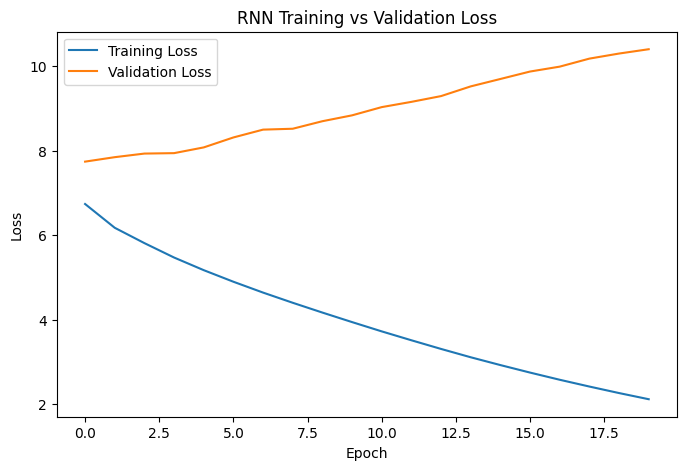

In [22]:
#Plot the loss

plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("RNN Training vs Validation Loss")

plt.legend()
plt.show()

In [23]:
#Predict the next word

def predict_next_word(seed_text):

    seed_text = seed_text.lower()

    sequence = tokenizer.texts_to_sequences([seed_text])[0]

    sequence = pad_sequences(
        [sequence],
        maxlen=sequence_length,
        padding="pre"
    )

    prediction = model.predict(sequence, verbose=0)

    predicted_word_index = np.argmax(prediction)

    return tokenizer.index_word[predicted_word_index]

In [24]:
print(predict_next_word("the time traveller"))

and


In [25]:
#Generate text

def generate_text(seed_text, num_words):

    for _ in range(num_words):

        sequence = tokenizer.texts_to_sequences([seed_text])[0]

        sequence = pad_sequences(
            [sequence],
            maxlen=sequence_length,
            padding="pre"
        )

        prediction = model.predict(sequence, verbose=0)

        predicted_index = np.argmax(prediction)

        predicted_word = tokenizer.index_word.get(
            predicted_index,
            ""
        )

        seed_text += " " + predicted_word

    return seed_text

In [27]:
print(generate_text("the time traveller", 20))

the time traveller and so iv time travelling i made my essay i felt it was a small array of the method surgings


In [28]:
#Save the model

model.save("time_machine_rnn.keras")